<h1>Импортирование библиотек</h1>

In [ ]:
import os
import kagglehub
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline
sns.set(color_codes=True)


<h1>Авторизация в Kaggle</h1>

In [ ]:
kagglehub.login()
path = kagglehub.dataset_download("parthfr/marvel-cinematic-universe-boxoffice-csv")


<h1>Первичный обзор данных</h1>

In [ ]:
files = os.listdir(path)

df = pd.read_csv(os.path.join(path, "mcu.csv"))

print(f"The shape of the dataset is: {df.shape}")

print("----------------------------------------------------------------------------------------------------------")

print(f"The first five rows from the dataset are:\n{df.head()}")

print("----------------------------------------------------------------------------------------------------------")

print(f"The last five rows from the dataset are:\n{df.tail()}")

print("----------------------------------------------------------------------------------------------------------")

print("The summary of the dataset is:")
df.info()


**Вывод:** датасет содержит 62 записи и 10 колонок. Часть финансовых колонок
(`movie_duration`, `production_budget`, `opening_weekend`, `domestic_box_office`,
`worldwide_box_office`) заполнена только у 38 из 62 строк — судя по `tail()`,
недостающие строки соответствуют ещё не вышедшим проектам (2026 год) и,
возможно, сериалам, для которых часть метрик неприменима.

<h1>Приведение типов</h1>

In [ ]:
df['release_date'] = pd.to_datetime(df['release_date'], format='%Y-%m-%d')


df['release_year'] = df['release_date'].dt.year

print(f"The datatype of each column in the dataset is:\n{df.dtypes}")

print("----------------------------------------------------------------------------------------------------------")

In [ ]:
df_dupcilate = df[df.duplicated()]
print("----------------------------------------------------------------------------------------------------------")
print(f"The number of duplicate rows in the dataset is: {df_dupcilate.shape[0]}")


**Вывод:** явных дубликатов строк в датасете не обнаружено.

<h1>Пропуски и числовые колонки</h1>

In [ ]:
print("----------------------------------------------------------------------------------------------------------")

print(f"The number of missing values in each column of the dataset is:\n{df.isnull().sum()}")


df_numerical = df.select_dtypes(include=["number"])

print(f"Original dataset shape: {df.shape}")
print(f"The numerical dataset shape: {df_numerical.shape} ")

print("----------------------------------------------------------------------------------------------------------")

print(f"The numerical dataset columns are:\n{df_numerical.columns}")

**Вывод:** 24 строки из 62 не имеют финансовых данных. Это не случайные
пропуски — они совпадают с проектами, которые ещё не вышли или являются
сериалами (X-Men '97, Daredevil: Born Again и т.д.), для которых
бокс-офис в принципе не существует. При дальнейшем финансовом анализе
имеет смысл явно отфильтровать такие строки, а не полагаться на то,
что seaborn/pandas сами их отбросят.

<h1>Поиск выбросов</h1>

In [ ]:
for column in df_numerical.columns:
    plt.figure(figsize=(10, 6))
    plt.title(f"Boxplot of {column}")
    sns.boxplot(x=df_numerical[column])
    plt.show()

In [ ]:
Q1 = df_numerical.quantile(0.25)
Q3 = df_numerical.quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = ((df_numerical < lower_bound) |
            (df_numerical > upper_bound))

print("The number of outliers in each column of the dataset is:\n", outliers.sum())

**Вывод:** по IQR-методу в финансовых колонках (бюджет, бокс-офис) есть
заметное число выбросов сверху — это ожидаемо для данных о сборах фильмов,
распределение которых обычно сильно скошено вправо (несколько блокбастеров
резко выделяются на фоне остальных). Удалять эти значения не стоит — это
не ошибки данных, а реальные хиты вроде "Мстителей". Для дальнейшего
статистического анализа лучше использовать логарифмическую трансформацию
этих колонок, а не отбрасывать выбросы.

<h1>Динамика по годам и фазам</h1>

In [ ]:

df['release_date'] = df['release_date'].dt.date

df['release_year'].value_counts().sort_index().plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Number of Movies by Release Year')
plt.xlabel('Release Year')
plt.ylabel('Number of Movies')

plt.show()

In [ ]:
yearly_rating = df.groupby('release_year')['tomato_meter'].mean()

plt.figure(figsize=(12, 6))

yearly_rating.plot()

plt.title('Average Tomato Meter by Release Year')
plt.xlabel('Release Year')
plt.ylabel('Average Tomato Meter')

plt.show()

In [ ]:
phase_counts = df['mcu_phase'].value_counts()

phase_counts.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Number of Movies by MCU Phase')
plt.xlabel('MCU Phase')
plt.ylabel('Number of Movies')

plt.show()

**Вывод:** Развитие MCU можно разделить на несколько этапов. В период 2008–2016 годов Marvel выпускала в среднем 1–2 фильма в год, постепенно формируя основу киновселенной. С 2017 по 2019 год темп увеличился до примерно трёх релизов ежегодно, а после 2020 года произошёл резкий рост: в 2021 году вышло около девяти проектов, а в последующие годы — по 4–8 в год.

Одновременно с увеличением количества контента начали меняться и оценки критиков. Наиболее успешным был период 2012–2019 годов, когда средние оценки составляли около 85–91%. После резкого расширения MCU оценки стали снижаться и достигли минимума примерно в 2023 году — около 68,5%. Это показывает возможную связь между перенасыщением контентом и снижением его среднего качества. При этом прогноз на 2026 год указывает на возможное восстановление оценок выше 91%.

Эти изменения хорошо заметны и по фазам MCU: первые две фазы включали по 6 проектов, третья — 11, а четвёртая и пятая выросли до 15 и 17 проектов соответственно. Шестая фаза сокращается примерно до 7 проектов, что может свидетельствовать о переходе Marvel от стратегии постоянного расширения к более сдержанному подходу и акценту на качестве.


<h1>Корреляции</h1>

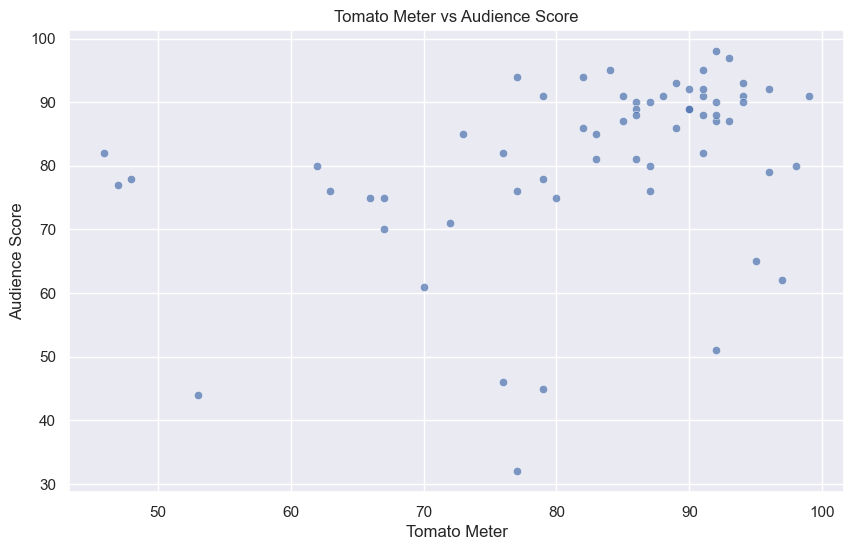

,tomato_meter,audience_score
tomato_meter,1.000000,0.368369
audience_score,0.368369,1.000000


In [13]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='tomato_meter',
    y='audience_score',
    alpha=0.7
)

plt.title('Tomato Meter vs Audience Score')
plt.xlabel('Tomato Meter')
plt.ylabel('Audience Score')

plt.show()

df[['tomato_meter', 'audience_score']].corr()

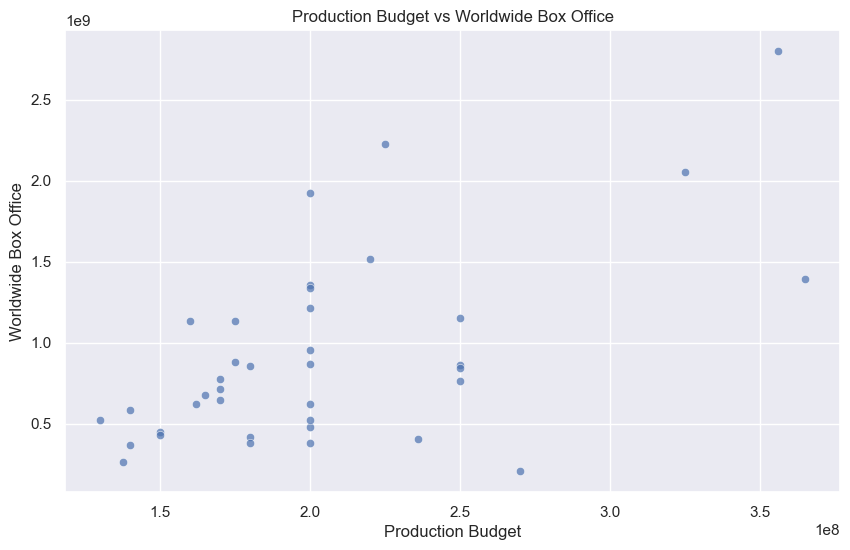

,production_budget,worldwide_box_office,domestic_box_office,opening_weekend
production_budget,1.000000,0.588256,0.496998,0.607731
worldwide_box_office,0.588256,1.000000,0.951817,0.948326
domestic_box_office,0.496998,0.951817,1.000000,0.956881
opening_weekend,0.607731,0.948326,0.956881,1.000000


In [14]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='production_budget',
    y='worldwide_box_office',
    alpha=0.7
)

plt.title('Production Budget vs Worldwide Box Office')
plt.xlabel('Production Budget')
plt.ylabel('Worldwide Box Office')

plt.show()

df[['production_budget' , 'worldwide_box_office' , 'domestic_box_office' , 'opening_weekend']].corr()

**Вывод:** Сравнение оценок критиков и зрителей показывает, что большинство фильмов MCU получают высокие оценки с обеих сторон — примерно 85–95% у критиков и 80–95% у аудитории. При этом встречаются проекты, где мнения значительно расходятся. Корреляция между показателями составляет **r = 0,368**, что говорит лишь об умеренно-слабой положительной связи: оценки критиков не всегда совпадают с мнением зрителей.

Между производственным бюджетом и мировыми сборами наблюдается более заметная зависимость (**r = 0,588**). Большинство фильмов с бюджетом $150–250 млн собирают от $400 млн до $1,5 млрд, а наиболее масштабные проекты способны приносить свыше $2 млрд. Однако высокий бюджет сам по себе не гарантирует успех. Бюджет сильнее связан с результатом первого уикенда (**r = 0,608**), тогда как дальнейшие сборы больше зависят от интереса аудитории и сарафанного радио. При этом показатели мировых, внутренних и стартовых сборов имеют очень высокую корреляцию (**r ≥ 0,95**), что указывает на тесную связь между успешным стартом фильма и его итоговыми кассовыми результатами.
